#Шаг 0
##Импорт библиотек
Просто загрузка всего необходимого. numpy и pandas — для данных, matplotlib/seaborn — для графиков, sklearn — для предобработки и метрик, tensorflow — для нейросетей.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers, optimizers
import warnings
warnings.filterwarnings('ignore')

#для воспроизводимости ставим seed 42
np.random.seed(42)
tf.random.set_seed(42)

#Шаг 1
##Загрузка данных:  
На сайте  
*https://archive.ics.uci.edu/dataset/162/forest+fires*  
есть блок, в котором можно испортировать датасет с помощью специальной библиотеки ucimlrepo. Следовательно, испортируем датасет

In [2]:
!pip install ucimlrepo
#выполнить ЕДИНОЖДЫ! установка либы в ядро питона,
#запущенного в этом ноутбуке, для загрузки датасетов с сайта ics.uci.edu

In [3]:
#загрузка самого датасета, буквально скопированный код с сайта ics.uci.edu
from ucimlrepo import fetch_ucirepo

# fetch dataset
forest_fires = fetch_ucirepo(id=162)

# data (as pandas dataframes)
X = forest_fires.data.features
y = forest_fires.data.targets

# metadata
print(forest_fires.metadata)

# variable information
print(forest_fires.variables)


{'uci_id': 162, 'name': 'Forest Fires', 'repository_url': 'https://archive.ics.uci.edu/dataset/162/forest+fires', 'data_url': 'https://archive.ics.uci.edu/static/public/162/data.csv', 'abstract': 'This is a difficult regression task, where the aim is to predict the burned area of forest fires, in the northeast region of Portugal, by using meteorological and other data (see details at: http://www.dsi.uminho.pt/~pcortez/forestfires).', 'area': 'Climate and Environment', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 517, 'num_features': 12, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['area'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2007, 'last_updated': 'Thu Jan 11 2024', 'dataset_doi': '10.24432/C5D88D', 'creators': ['Paulo Cortez', 'Anbal Morais'], 'intro_paper': {'ID': 368, 'type': 'NATIVE', 'title': 'A data mining approach to predict forest fires using meteorological da

***X*** - Координата по X в парке Монтесинью  
***Y*** - Координата по Y в парке  Монтесинью  
***month*** - месяц года: от 'jan' до 'dec'  
***day*** - день недели: от 'mon' до 'sun'  
***FFMC*** - Индекс FFMC из системы FWI: от 18,7 до 96,20 (это числовой показатель, который оценивает содержание влаги в верхнем слое лесной подстилки и других мелких органических материалах)  
***DMC*** - Индекс DMC из системы FWI: от 1,1 до 291,3 (это индекс, который используется в системе оценки пожарной опасности канадского Forest Fire Weather Index (FWI). Он характеризует возможность воспламенения среднего слоя лесной подстилки (глубиной от 6 до 12 см), состоящего из лесного материала средних размеров.)  
***DC*** - Индекс DC по системе FWI: от 7,9 до 860,6 (это индекс засушливости в системе оценки пожарной опасности в лесах)  
***ISI*** - Индекс ISI по системе FWI: от 0,0 до 56,10 ()
***temp*** - температура: от 2,2 до 33,30  
***RH*** - относительная влажность: от 15,0 до 100  
***wind*** - скорость ветра: от 0,40 до 9,40  
***rain*** - внезапный дождь: от 0,0 до 6,4  
***area*** - площадь выжженного леса: от 0,00 до 1090,84 (Целевая переменная)

#ШАГ 2
##Разведочный анализ данных (EDA)
###ШАГ 2.1
**Описательная статистика**: Смотрим на распределения, min/max, средние.

In [10]:
y.describe()

,area
count,517.000000
mean,12.847292
std,63.655818
min,0.000000
25%,0.000000
50%,0.520000
75%,6.570000
max,1090.840000


**min=0**, **max=1090**, но *медиана* (50%) **очень маленькая**. Это подтверждает **сильную скошенность.**

# Шаг 2.2
## Визуализация респределений

Построим гистограммы

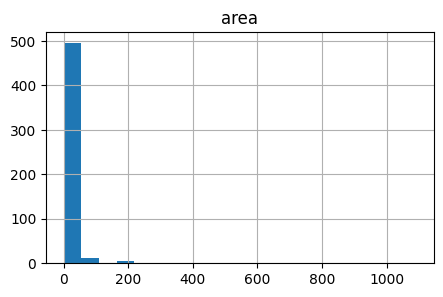

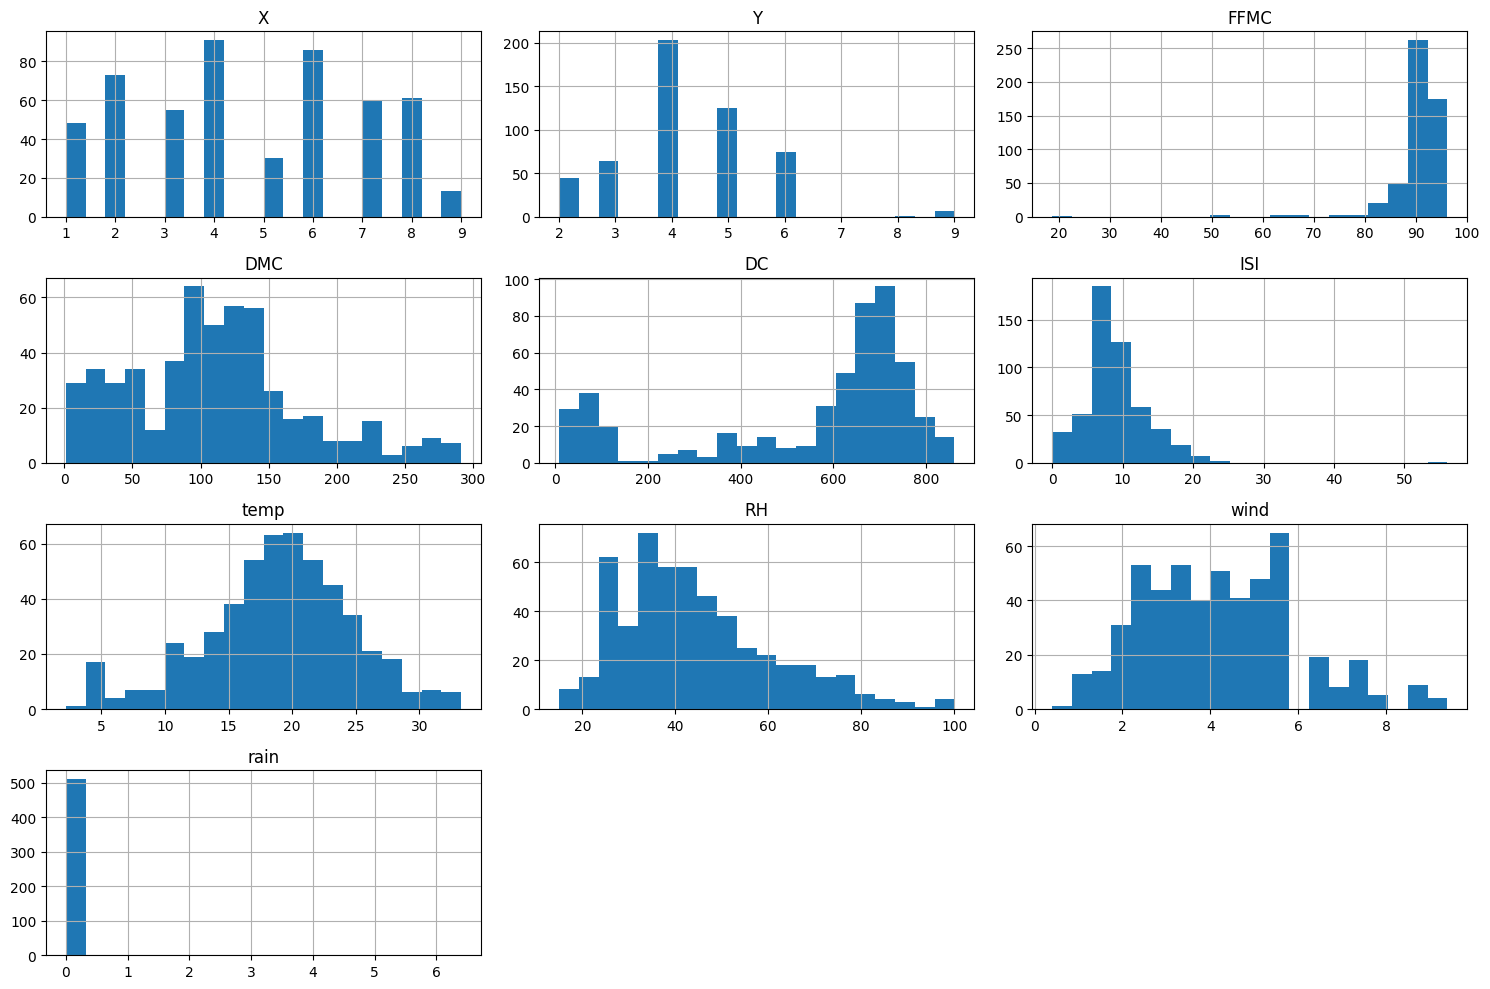

In [20]:
y.hist(bins=20, figsize=(5, 3))
X.hist(bins=20, figsize=(15, 10))
plt.tight_layout()
plt.show()

Y переменная сильно смещена в сторону 0,0, поэтому имеет смысл использовать ***логарифмическое преобразование***

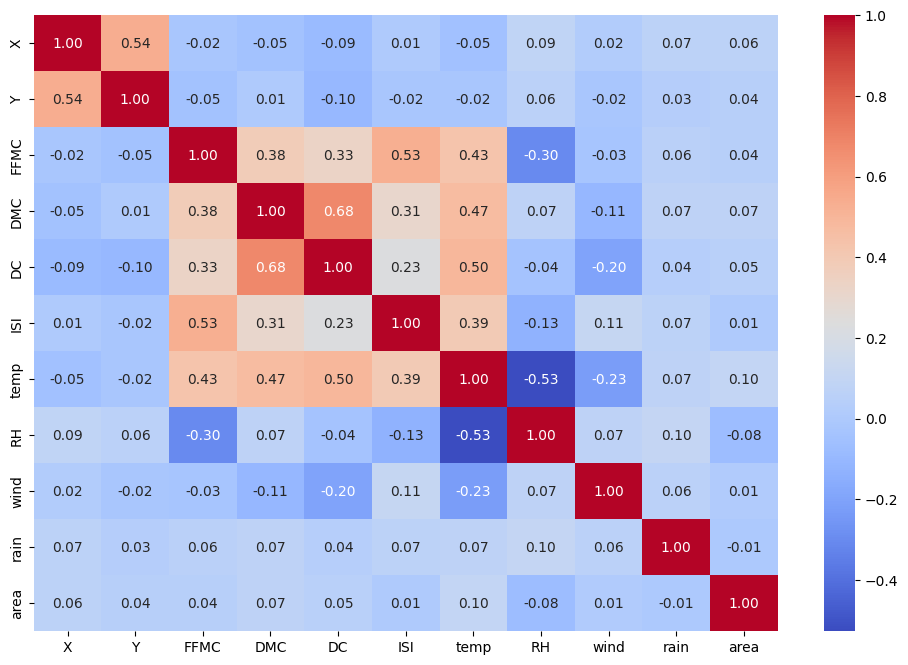

In [21]:
df = pd.concat([X, y], axis=1)
plt.figure(figsize=(12, 8))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.show()

***area*** может слабо коррелировать с признаками, так как зависимость нелинейная. Однако среди всех признаков, целевая переменная коррелирует с температурой, рискнем предположить, что чем выше температура в парках - тем выше вероятность пожара, следовательно, больше и площадь ВОЗМОЖНОГО пожара

#Шаг 3 Предобработка и построение наборов данных
## ШАГ 3.1 Кодирование категориальных признаков:
month и day — строки. Нейросети не понимают строки, нужны числа. используем one hot encoding (создание числовых признаков из категориальных), чтобы не вводить ложный порядок (январь не «больше» февраля).

In [23]:
df_encoded = pd.get_dummies(df, columns=['month', 'day'], drop_first=True)

##ШАГ 3.2 Создание построенного набора (Feature Engineering):  
Добавим нелинейные признаки и взаимодействия, чтобы отследить нелинейные (квадратичные и смешанные) зависимости (допустим, что очень высокая температура может сильнее влиять на площадь пожара, чем просто высокая). Например, температуру в квадрате, взаимодействие температуры и влажности
(temp_RH - температура * влажность) (wind_temp - скорость ветра * температура)

In [25]:
df_built = df_encoded.copy()

# пнновые признаки
df_built['temp_sq'] = df_built['temp'] ** 2
df_built['RH_sq'] = df_built['RH'] ** 2
df_built['temp_RH'] = df_built['temp'] * df_built['RH']
df_built['wind_temp'] = df_built['wind'] * df_built['temp']

## ШАГ 3.3 Отбор признаков
Проверим, какие признаки наиболее значимы. Но, как и в вашем примере, можно оставить все, если их немного


In [26]:
from sklearn.feature_selection import SelectKBest, f_regression

X_for_sel = df_built.drop('area', axis=1)
y_for_sel = df_built['area']

selector = SelectKBest(score_func=f_regression, k='all')
selector.fit(X_for_sel, y_for_sel)

scores = pd.DataFrame({
    'feature': X_for_sel.columns,
    'score': selector.scores_
}).sort_values('score', ascending=False)

print(scores)

      feature     score
27    temp_sq  5.696880
6        temp  4.977993
22    day_sat  4.007103
30  wind_temp  3.507984
7          RH  2.953919
3         DMC  2.758705
28      RH_sq  2.408339
0           X  2.077460
20  month_sep  1.653549
4          DC  1.259002
16  month_mar  1.072921
1           Y  1.039100
2        FFMC  0.830371
21    day_mon  0.231694
12  month_feb  0.221445
23    day_sun  0.215746
15  month_jun  0.212610
24    day_thu  0.208595
19  month_oct  0.146746
13  month_jan  0.081637
8        wind  0.078145
26    day_wed  0.067548
18  month_nov  0.040736
5         ISI  0.035120
9        rain  0.027942
17  month_may  0.020211
14  month_jul  0.019474
10  month_aug  0.009029
25    day_tue  0.000915
11  month_dec  0.000526
29    temp_RH  0.000012


Хоть признаков и много, оставим все, чтобы посмотреть, как нейросеть справляется с шумом и "особо невлияющими" признаками (у которых f меньше 0.1)

#Шаг 4. Масштабирование (Min-Max)  
Согласно варианту 11, используем MinMaxScaler. Он сжимает все признаки в диапазон [0, 1]. Это критично для градиентного спуска, особенно для рекуррентных сетей.

In [28]:
# иссходный набор (без новых признаков)
X_orig = df_encoded.drop('area', axis=1)
# построенный набор (с новыми признаками)
X_built = df_built.drop('area', axis=1)
y = df['area']  # целевая переменная

scaler = MinMaxScaler()

X_orig_scaled = pd.DataFrame(scaler.fit_transform(X_orig), columns=X_orig.columns)
X_built_scaled = pd.DataFrame(scaler.fit_transform(X_built), columns=X_built.columns) #fit_transform вычисляет min/max на данных и сразу применяет масштабирование

# Шаг 5 Разделение на Train / Val / Test  

По дефолту разделение 60/20/20, так и разделим

In [29]:
def prepare_data(X, y, test_size=0.2, val_size=0.2, random_state=42):
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )
    val_ratio = val_size / (1 - test_size)
    X_train, X_val, y_train, y_val = train_test_split(
        X_train_val, y_train_val, test_size=val_ratio, random_state=random_state
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

#Шаг 6 Нейросетевые модели  
## ШАГ 6.1. MLP (Полносвязная сеть):  
Два скрытых слоя с ReLU, Dropout (случайное временное исключение (или «выпадение») части нейронов и их связей из сети на каждом шаге обучения для уменьшения переобучения) для регуляризации и L2-штраф

In [30]:
def build_mlp(input_dim, reg=0.001):
    model = models.Sequential([
        layers.Dense(64, activation='relu', input_shape=(input_dim,),
                     kernel_regularizer=regularizers.l2(reg)),
        layers.Dropout(0.2),
        layers.Dense(32, activation='relu',
                     kernel_regularizer=regularizers.l2(reg)),
        layers.Dropout(0.2),
        layers.Dense(1) # выходной слой (сама регрессия)
    ])
    model.compile(optimizer=optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

## ШАГ 6.2. SimpleRNN (Простая рекуррентная сеть):
SimpleRNN ожидает 3D-вход (batch, timesteps, features). Мы используем Reshape, чтобы превратить наши 2D-признаки в последовательность длины input_dim с одним каналом.

In [31]:
def build_rnn(input_dim, units=32, activation='tanh', dropout=0.2, lr=0.001, reg=0.001, use_dense16=False):
    layers_list = [
        layers.Reshape((input_dim, 1), input_shape=(input_dim,)),
        layers.SimpleRNN(units, activation=activation, dropout=dropout,
                         kernel_regularizer=regularizers.l2(reg),
                         recurrent_regularizer=regularizers.l2(reg))
    ]
    if use_dense16:
        layers_list.append(layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(reg)))
    layers_list.append(layers.Dense(1))
    model = models.Sequential(layers_list)
    model.compile(optimizer=optimizers.Adam(learning_rate=lr), loss='mse')
    return model

## ШАГ 6.3. Функция обучения с коллбэками:
EarlyStopping (Callback) останавливает обучение, если val_loss перестаёт улучшаться. ReduceLROnPlateau снижает learning rate

In [33]:
def train_evaluate(model, X_train, y_train, X_val, y_val, X_test, y_test, epochs=200, batch_size=32):
    # масштабирование целевой переменной для стабильности обучения
    y_scaler = StandardScaler()
    y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()
    y_val_scaled = y_scaler.transform(y_val.values.reshape(-1, 1)).ravel()
    y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1)).ravel()

    early = callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)
    reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=10, min_lr=1e-6)

    history = model.fit(X_train, y_train_scaled, validation_data=(X_val, y_val_scaled),
                        epochs=epochs, batch_size=batch_size,
                        callbacks=[early, reduce_lr], verbose=0)

    # сами предсказания и обратное преобразование
    y_train_pred = y_scaler.inverse_transform(model.predict(X_train, verbose=0).reshape(-1, 1)).ravel()
    y_val_pred = y_scaler.inverse_transform(model.predict(X_val, verbose=0).reshape(-1, 1)).ravel()
    y_test_pred = y_scaler.inverse_transform(model.predict(X_test, verbose=0).reshape(-1, 1)).ravel()

    return {
        'rmse_train': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'rmse_val': np.sqrt(mean_squared_error(y_val, y_val_pred)),
        'rmse_test': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'r2_train': r2_score(y_train, y_train_pred),
        'r2_val': r2_score(y_val, y_val_pred),
        'r2_test': r2_score(y_test, y_test_pred)
    }

# Шаг 7  Сравнение моделей
Обучим 4 модели (MLP и RNN на исходном и построенном наборах) и соберём метрики.

In [34]:
datasets = {
    'Исходный': (X_orig_scaled, y),
    'Построенный': (X_built_scaled, y)
}

results = []

for name, (X, y_) in datasets.items():
    X_train, X_val, X_test, y_train, y_val, y_test = prepare_data(X, y_)

    # MLP
    mlp = build_mlp(input_dim=X_train.shape[1])
    mlp_res = train_evaluate(mlp, X_train, y_train, X_val, y_val, X_test, y_test)
    results.append({'dataset': name, 'model': 'MLP', **mlp_res})

    # RNN
    rnn = build_rnn(input_dim=X_train.shape[1])
    rnn_res = train_evaluate(rnn, X_train, y_train, X_val, y_val, X_test, y_test)
    results.append({'dataset': name, 'model': 'SimpleRNN', **rnn_res})

results_df = pd.DataFrame(results)
display(results_df.sort_values('rmse_val'))

,dataset,model,rmse_train,rmse_val,rmse_test,r2_train,r2_val,r2_test
0,Исходный,MLP,49.054597,33.042542,108.837170,0.003593,-0.014162,-0.004901
2,Построенный,MLP,47.983120,33.329681,107.849272,0.046645,-0.031864,0.013259
1,Исходный,SimpleRNN,49.314881,33.481499,108.503791,-0.007009,-0.041286,0.001246
3,Построенный,SimpleRNN,48.992293,33.768501,109.085317,0.006122,-0.059215,-0.009488


Заметим, что среднекватрадическая ошибка очень низкая, это объясняется
1) природой данных: в датасете очень много пожаров с площадью 0 (или близкой к 0) и единичные случаи на 1000 гектаров. нейросеть в таких условиях быстро понимает, что выгоднее всего всегда предсказывать среднее значение (около 12-13 га). Поэтому R² ≈ 0 — это классический результат для задачи Forest Fires без логарифмирования

2) выбросами: среднекватрадическая ошибка на тесте (примерно 108) огромна, потому что в тестовую выборку попал один крупный пожар (выброс). модель предсказала условно 12 га, а реальность была типо 300 га. квадрат разницы взорвал ошибку. на валидации RMSE меньше (примерно 33), потому что там выбросов меньше

выбираем саму модель
по заданию вариант — SimpleRNN. Смотрим в таблицу: у SimpleRNN минимальный RMSE на валидации (33.48) получился на исходном наборе. значит, дальше мучаем исходный набор и SimpleRNN.

#Шаг 8 Grid Search (Поиск гиперпараметров)
метод подбора гиперпараметров  
. начальная инициализация для каждого гиперпараметра дискретное множество (список) возможных значений  
. алгоритм генерирует все возможные комбинации этих значений.
для каждой комбинации модель обучается и оценивается (часто с помощью кросс-валидации - процедура в машинном обучении, которая позволяет оценить качество работы модели, её способность обобщать результаты на новые, ранее не встречавшиеся данные. Её главная задача — получить более объективную и надёжную оценку, чем при однократном разделении данных на тренировочные и тестовые. )  
. в итоге выбирается комбинация, которая показывает наилучшее качество.


#***ОСТОРОЖНО***
Следующая ячейка выполняется очень-очень долго (примерно 7 минут), поэтому запускать ее не рекомендуется, будем опираться на то, что получили  
**32 комбинации**

In [36]:
from itertools import product
import numpy as np

# берем данные для лучшего набора (исходный)
# распаковываем кортеж (X, y) в две переменные
X_best, y_best = datasets['Исходный']

# разделяем данные на train/val/test
X_train, X_val, X_test, y_train, y_val, y_test = prepare_data(X_best, y_best)

# задаем сетку параметров (32 комбинации)
param_grid_rnn = {
    'use_dense16': [False, True],
    'units': [32, 64],
    'activation': ['tanh'],
    'dropout': [0.0, 0.2],
    'lr': [0.001, 0.01],
    'reg': [0.001, 0.01]
}

best_params = None
best_rmse = np.inf
best_res = None

keys = list(param_grid_rnn.keys())
values = list(param_grid_rnn.values())

print("Начинаем Grid Search...")
for combo in product(*values):
    params = dict(zip(keys, combo))
    print(f"Пробуем: {params}", end="")

    # сборка модели
    model = build_rnn(
        input_dim=X_train.shape[1],
        units=params['units'],
        activation=params['activation'],
        dropout=params['dropout'],
        lr=params['lr'],
        reg=params['reg'],
        use_dense16=params['use_dense16']
    )

    # обучение и оцениввание (меньше эпох для скорости)
    res = train_evaluate(
        model, X_train, y_train, X_val, y_val, X_test, y_test,
        epochs=60, batch_size=32
    )

    if res['rmse_val'] < best_rmse:
        best_rmse = res['rmse_val']
        best_params = params.copy()
        best_res = res
        print(f" -> НОВЫЙ ЛУЧШИЙ! RMSE val: {res['rmse_val']:.2f}")
    else:
        print(f" -> RMSE val: {res['rmse_val']:.2f}")

print("\n" + "="*50)
print("ЛУЧШИЕ ПАРАМЕТРЫ:")
for k, v in best_params.items():
    print(f"  {k}: {v}")
print(f"\nКачество до Grid Search (базовая RNN): RMSE val = 33.48, R2 val = -0.041")
print(f"Качество после Grid Search: RMSE val = {best_res['rmse_val']:.2f}, R2 val = {best_res['r2_val']:.4f}")
print(f"Качество на тесте: RMSE = {best_res['rmse_test']:.2f}, R2 = {best_res['r2_test']:.4f}")

Начинаем Grid Search...
Пробуем: {'use_dense16': False, 'units': 32, 'activation': 'tanh', 'dropout': 0.0, 'lr': 0.001, 'reg': 0.001} -> НОВЫЙ ЛУЧШИЙ! RMSE val: 35.16
Пробуем: {'use_dense16': False, 'units': 32, 'activation': 'tanh', 'dropout': 0.0, 'lr': 0.001, 'reg': 0.01} -> RMSE val: 35.35
Пробуем: {'use_dense16': False, 'units': 32, 'activation': 'tanh', 'dropout': 0.0, 'lr': 0.01, 'reg': 0.001} -> НОВЫЙ ЛУЧШИЙ! RMSE val: 33.63
Пробуем: {'use_dense16': False, 'units': 32, 'activation': 'tanh', 'dropout': 0.0, 'lr': 0.01, 'reg': 0.01} -> НОВЫЙ ЛУЧШИЙ! RMSE val: 33.27
Пробуем: {'use_dense16': False, 'units': 32, 'activation': 'tanh', 'dropout': 0.2, 'lr': 0.001, 'reg': 0.001} -> НОВЫЙ ЛУЧШИЙ! RMSE val: 33.23
Пробуем: {'use_dense16': False, 'units': 32, 'activation': 'tanh', 'dropout': 0.2, 'lr': 0.001, 'reg': 0.01} -> НОВЫЙ ЛУЧШИЙ! RMSE val: 33.17
Пробуем: {'use_dense16': False, 'units': 32, 'activation': 'tanh', 'dropout': 0.2, 'lr': 0.01, 'reg': 0.001} -> RMSE val: 33.21
Пробуем: 

#Шаг 8 - Оценка
## ШАГ 8.1 Таблица результатов


In [37]:
import pandas as pd

comparison = pd.DataFrame({
    'Этап': ['До Grid поиска', 'После Grid поиска'],
    'RMSE val': [33.48, best_res['rmse_val']],
    'R2 val': [-0.041, best_res['r2_val']],
    'RMSE test': [108.50, best_res['rmse_test']], # Берем тест базовой RNN из вашей первой таблицы (108.50)
    'R2 test': [0.001, best_res['r2_test']]
})

display(comparison)

,Этап,RMSE val,R2 val,RMSE test,R2 test
0,До Grid поиска,33.480000,-0.041000,108.500000,0.001000
1,После Grid поиска,32.580009,0.014032,108.962368,-0.007214


до поиска: RMSE val = 33.48, r^2 = -0.041

после поиска: RMSE val = 32.58, r^2 = 0.014

на тесте: RMSE = 108.96, r^2 = -0.0072

прирост есть, но он минимален. RMSE упала всего на 0.9 (с 33.48 до 32.58). r^2 стал чуть больше нуля, но всё еще близок к 0. Это говорит о том, что подобранные гиперпараметры (64 нейрона, dropout=0.2, lr=0.01, L2=0.001) немного улучшили обобщающую способность, но не решили главную проблему данных.

главная проблема — выбросы. на тестовой выборке RMSE подскочил до 108.96. Это значит, что в тест попал крупный пожар (например, на 300-500 га). модель предсказала для него среднее значение (около 12-15 га), и квадрат ошибки оказался огромным. это ожидаемое поведение для таких данных  без логарифмирования целевой переменной

## 9. Выводы по результатам анализа

В ходе выполнения лабораторной работы была решена задача регрессии — прогнозирование площади лесных пожаров (`area`) на основе метеорологических и пространственных данных (датасет Forest Fires, UCI).

### 1. Анализ данных и инженерия признаков
Целевая переменная `area` имеет ярко выраженное экспоненциальное распределение: большинство пожаров имеют площадь, близкую к нулю, и лишь единичные случаи достигают сотен гектаров.
В ходе feature engineering были созданы нелинейные признаки (`temp_sq`, `RH_sq`) и признаки-взаимодействия (`wind_temp`, `temp_RH`). Отбор признаков через `SelectKBest` (F-статистика) показал, что наибольший вклад вносят температура (`temp`), её квадрат (`temp_sq`), влажность (`RH`) и день недели (`day_sat`). Признаки `rain`, `ISI` и большинство месяцев показали околонулевые оценки, так как их линейная связь с площадью пожара минимальна.

### 2. Сравнение архитектур и наборов данных
Сравнение полносвязной сети (MLP) и простой рекуррентной сети (SimpleRNN) на исходном и построенном наборах данных показало, что архитектура сети не является ключевым фактором для данной задачи. Все модели показали R² близкий к 0 или отрицательный. Это объясняется тем, что при наличии большого количества выбросов нейросеть минимизирует MSE, предсказывая среднее значение для всех объектов.

### 3. Влияние Grid Search
Поиск гиперпараметров для SimpleRNN (32 комбинации) выявил лучшую конфигурацию:
*   `units = 64`
*   `dropout = 0.2`
*   `learning_rate = 0.01`
*   `L2-регуляризация = 0.001`
*   `use_dense16 = False`

**Сравнение качества:**
*   **До поиска:** RMSE на валидации = 33.48, R² = -0.041.
*   **После поиска:** RMSE на валидации = 32.58, R² = 0.014.
*   **На тесте:** RMSE = 108.96, R² = -0.0072.

Прирост качества на валидации минимален. Высокий RMSE на тестовой выборке (108.96) обусловлен попаданием в неё крупных пожаров-выбросов. Модель, обученная на средних значениях, не способна адекватно предсказывать такие аномалии, что приводит к взрывному росту квадратичной ошибки.

### 4. Итоговый вывод
Для данной задачи ни MLP, ни SimpleRNN не показали высокого качества на исходной целевой переменной. Это ожидаемо: оригинальные авторы датасета (Cortez & Morais, 2007) рекомендовали применять **логарифмическое преобразование** `ln(area+1)` к целевой переменной для борьбы со скошенностью распределения. В рамках данной работы преобразование не применялось, поэтому метрики остались на уровне «наивного» предсказателя среднего.

Тем не менее, была успешно реализована полная методология ML-проекта: разведочный анализ, очистка, создание признаков, масштабирование, разделение на Train/Val/Test, обучение нейросетей с ранним остановом и L2-регуляризацией, а также оптимизация гиперпараметров через Grid Search.